# 00 - The story: monocular foundation-model SLAM on a ground robot

This notebook walks through Elias's part of the project from question to conclusions. It only **reads** what the
pipeline produced (`results/`, `data/M3DGR/`), so it runs in a few minutes; nothing is re-run on the GPU.

**Question.** How well does a 3D foundation model turned into SLAM - **VGGT-Long** (Deng et al., ICRA 2026), recommended
by the lecturer - work on a wheeled indoor robot with one RGB camera, and where does it fail? Does a model that
predicts **metric** depth (**MapAnything**, Keetha et al., 3DV 2026) fix the missing scale of a single camera?

**Contents**
1. Data: robot, sequences, what makes each one hard
2. A pseudo-ground-truth map from LiDAR + motion capture
3. VGGT-Long: trajectories (ATE)
4. Why `Varying-illu01` fails: error vs. image brightness
5. Maps against the pseudo ground truth
6. MapAnything in the same pipeline ("Map-Long")
7. Repeatability and resources
8. Take-aways

Prerequisites: the three sequences downloaded and prepared (README, section *Data*), `python -m pipeline.evaluate`,
`python -m pipeline.reference_map --sequence <seq>` and `python -m pipeline.map_eval`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from evo.tools import file_interface

from pipeline.common import load_sequences
from pipeline.visualize import align_full, robot_state, _read_ply_xyzrgb

plt.style.use(ROOT / "paper" / "ieee.mplstyle")
from cycler import cycler
# the paper style cycles markers for few-point series; dense time series and paths become blobs with them
plt.rcParams["axes.prop_cycle"] = cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#000000", "#56B4E9"]) +     cycler(linestyle=["-", "--", "-.", ":", "-", "--"])
pd.set_option("display.precision", 3)
CFG = load_sequences()
DATA = ROOT / CFG["data_root"]
SEQS = [s["name"] for s in CFG["sequences"]]
FIG = ROOT / "paper" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
gt = {s: file_interface.read_tum_trajectory_file(str(DATA / s / "gt_tum.txt")) for s in SEQS}

## 1. Data

**M3DGR** (Zhang et al., IROS 2025): a differential-drive robot with two Livox LiDARs (MID-360, Avia), a RealSense D435i
(RGB-D + IMU), an Insta360 camera and wheel odometry, recorded in a motion-capture hall (OptiTrack, ~300 Hz).
We use three indoor sequences in the same room (~6.5 m x 3 m). Two are well lit, because a robot mostly works in normal
light; darkness is included **once** as a stress test for cameras.

The table below is measured from the recordings: image brightness (mean grey value of every 15th frame) and the driving
state (`pipeline.visualize.robot_state`: speed from mocap, wheel slip = wheel speed - true speed, yaw rate).

In [2]:
def brightness(seq, step=15):
    lines = [l.split() for l in (DATA / seq / "rgb.txt").read_text().splitlines() if not l.startswith("#")]
    t0 = float(lines[0][0])
    out = []
    for t, f in lines[::step]:
        g = cv2.imread(str(DATA / seq / f), cv2.IMREAD_GRAYSCALE)
        out.append((float(t) - t0, g.mean(), (g < 20).mean()))
    return np.array(out)

light = {s: brightness(s) for s in SEQS}
state = {}
for s in SEQS:
    by = {}
    for topic, _, t, m in robot_state(DATA / f"{s}.bag", gt[s], CFG):
        by.setdefault(topic.split("/")[-1], []).append((t, m.data))
    state[s] = {k: np.array(v) for k, v in by.items()}

rows = []
for s in SEQS:
    st, g = state[s], gt[s]
    rows.append({"sequence": s,
                 "duration_s": g.timestamps[-1] - g.timestamps[0],
                 "path_m": st["distance"][-1, 1],
                 "speed_median_m_s": np.median(st["speed_gt"][:, 1]),
                 "speed_max_m_s": st["speed_gt"][:, 1].max(),
                 "yaw_rate_p99_deg_s": np.percentile(np.abs(st["yaw_rate_gt"][:, 1]), 99),
                 "wheel_slip_max_m_s": np.abs(st["wheel_slip"][:, 1]).max(),
                 "brightness_mean": light[s][:, 1].mean(),
                 "near_black_frames_%": 100 * (light[s][:, 2] > 0.8).mean()})
pd.DataFrame(rows).set_index("sequence")

,duration_s,path_m,speed_median_m_s,speed_max_m_s,yaw_rate_p99_deg_s,wheel_slip_max_m_s,brightness_mean,near_black_frames_%
sequence,,,,,,,,
Dynamic01,175.15,71.407,0.441,0.714,20.381,0.231,125.766,0.000
Sha-turn01,138.95,97.795,0.758,1.597,36.262,0.496,129.161,0.000
Varying-illu01,154.08,72.249,0.500,0.958,22.721,0.254,76.989,46.104


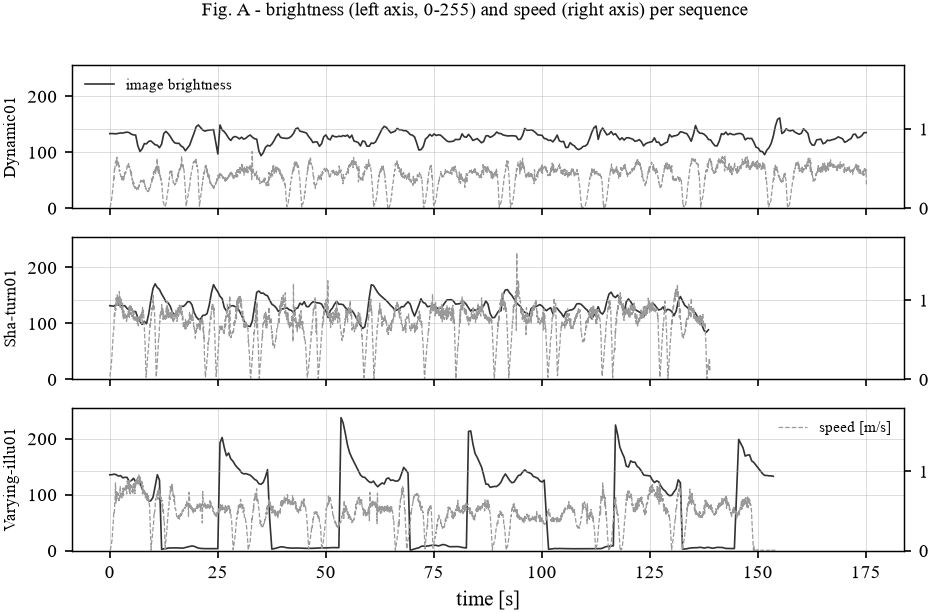

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(7.16, 4.2), sharex=True)
for ax, s in zip(axes, SEQS):
    ax.plot(light[s][:, 0], light[s][:, 1], color="0.2", lw=0.8, label="image brightness")
    ax.set_ylabel(s, fontsize=8); ax.set_ylim(0, 255)
    ax2 = ax.twinx()
    sp = state[s]["speed_gt"]
    ax2.plot(sp[:, 0] - gt[s].timestamps[0], sp[:, 1], color="0.6", lw=0.6, ls="--", label="speed [m/s]")
    ax2.set_ylim(0, 1.8)
axes[0].legend(loc="upper left", fontsize=7); ax2.legend(loc="upper right", fontsize=7)
axes[-1].set_xlabel("time [s]")
fig.suptitle("Fig. A - brightness (left axis, 0-255) and speed (right axis) per sequence", fontsize=9)
fig.savefig(FIG / "sequences_brightness_speed.pdf")

**Reading the table and Fig. A:** `Dynamic01` is the nominal case (well lit, slow, people walking by). `Sha-turn01`
is twice as fast with sharp turns and up to ~0.5 m/s wheel slip. In `Varying-illu01` the light is switched off
repeatedly; a large share of the frames is near-black for up to ~10 s at a time.

## 2. A pseudo-ground-truth map

M3DGR has no reference map. Following the lecturer's suggestion, `pipeline/reference_map.py` places the MID-360 scans
with the motion-capture poses, every point at its own timestamp. The transform between the mocap body and the robot is
**not** in the dataset; it is estimated by maximising map consistency (Levinson & Thrun 2010 style). Three independent
estimates (one per sequence) agree to ~0.1 deg / 1 cm, so their mean is used. A persistence filter removes people
walking through `Dynamic01`. Limitation: the reference comes from the MID-360, which favours systems using that LiDAR.

body -> base: {'roll_deg': 1.66, 'pitch_deg': -0.764, 'yaw_deg': 184.542, 'x_m': 0.019, 'y_m': -0.094}
LiDAR-mocap time offset [s]: {'Dynamic01': 0.0176, 'Sha-turn01': 0.0074, 'Varying-illu01': 0.0109}


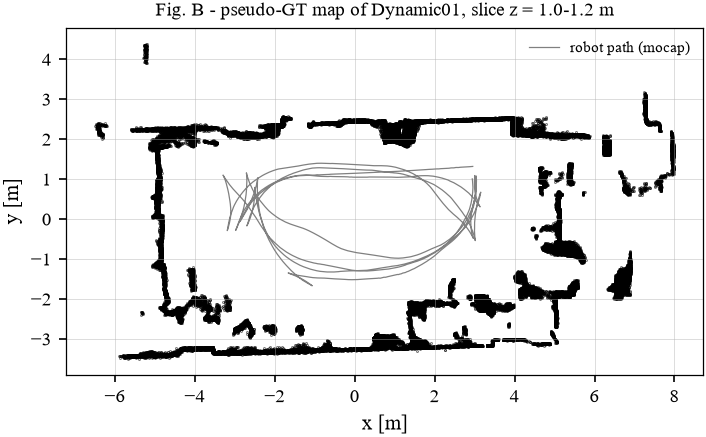

In [4]:
rm = CFG["reference_map"]
print("body -> base:", rm["body_T_base"])
print("LiDAR-mocap time offset [s]:", rm["time_offset_s"])
ref = {s: _read_ply_xyzrgb(DATA / s / "reference_map.ply")[0] for s in SEQS}
fig, ax = plt.subplots(figsize=(7.16, 3.0))
p = ref["Dynamic01"]
sl = (p[:, 2] > 1.0) & (p[:, 2] < 1.2)
ax.scatter(p[sl, 0], p[sl, 1], s=0.05, c="k", rasterized=True)
ax.plot(gt["Dynamic01"].positions_xyz[::30, 0], gt["Dynamic01"].positions_xyz[::30, 1], lw=0.6, c="0.5",
        label="robot path (mocap)")
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.legend(loc="upper right", fontsize=7)
ax.set_title("Fig. B - pseudo-GT map of Dynamic01, slice z = 1.0-1.2 m", fontsize=9)
fig.savefig(FIG / "reference_map_slice.pdf")

## 3. VGGT-Long: trajectories

VGGT-Long cuts the image stream into overlapping chunks of 60 frames (10 Hz input), reconstructs each chunk with the
VGGT foundation model, aligns neighbouring chunks with Sim(3) and closes loops. A single camera cannot observe metric
scale, so trajectories are compared after **Sim(3)** alignment (Umeyama 1991, Zhang & Scaramuzza 2018); the scale factor
is reported. 5 runs per sequence on a 48 GB GPU (the default chunk size needs ~31.6 GB, more than a 16 GB laptop GPU).

In [5]:
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
vg = metrics[metrics.slug == "vggt_long"]
vg.groupby("sequence").agg(runs=("run", "count"), successes=("success", "sum"),
                            ate_rmse_m=("ate_rmse_m", "median"), ate_rmse_iqr_m=("ate_rmse_m", lambda x: x.quantile(.75) - x.quantile(.25)),
                            ate_max_m=("ate_max_m", "median"), scale=("scale", "median"),
                            tracked_fraction=("tracked_fraction", "median")).loc[SEQS]

,runs,successes,ate_rmse_m,ate_rmse_iqr_m,ate_max_m,scale,tracked_fraction
sequence,,,,,,,
Dynamic01,5,5,0.146,1.120e-05,0.290,5.241,0.999
Sha-turn01,5,5,0.264,4.601e-06,0.647,5.811,0.999
Varying-illu01,5,5,2.346,4.533e-07,3.425,2.076,0.999


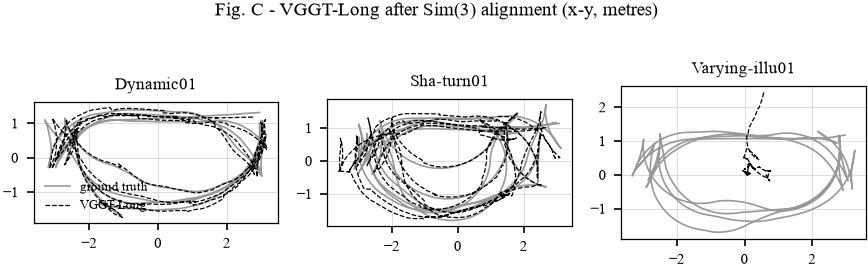

In [6]:
def aligned(slug, seq, sim3=True):
    est = file_interface.read_tum_trajectory_file(str(ROOT / "results" / slug / seq / "run_00" / "trajectory_tum.txt"))
    return align_full(gt[seq], est, sim3, CFG["evaluation"]["t_max_diff"])

fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.2))
for ax, s in zip(axes, SEQS):
    e, (sc, _, _) = aligned("vggt_long", s)
    ax.plot(gt[s].positions_xyz[::30, 0], gt[s].positions_xyz[::30, 1], c="0.6", lw=0.8, label="ground truth")
    ax.plot(e.positions_xyz[:, 0], e.positions_xyz[:, 1], c="k", lw=0.6, label="VGGT-Long")
    ax.set_aspect("equal"); ax.set_title(s, fontsize=8); ax.tick_params(labelsize=7)
axes[0].legend(fontsize=6, loc="lower left")
fig.suptitle("Fig. C - VGGT-Long after Sim(3) alignment (x-y, metres)", fontsize=9)
fig.savefig(FIG / "vggt_long_trajectories.pdf")

**Reading Fig. C:** on the two well-lit sequences VGGT-Long follows the ground truth closely (0.15 m and 0.26 m
ATE on ~70-100 m of driving, i.e. ~0.2-0.3 % of the distance). On `Varying-illu01` the trajectory collapses into a small
tangle - although every frame got a pose (tracked fraction 99.9 %).

## 4. Why `Varying-illu01` fails: a silent failure

Classical visual SLAM reports *tracking lost* when the image is black. VGGT-Long does not: it predicts a pose and a depth
map for every frame. Chunks made of black frames have no usable geometry, so the Sim(3) alignment between neighbouring
chunks estimates wrong relative scales, and the error propagates to everything after it. Fig. D shows the consequence:
the error is **not** confined to the dark phases - it oscillates with every lap (0.5-3.4 m) over the whole sequence,
because the entire reconstruction has shrunk (scale factor ~2.1 instead of ~5.5). The **tracked fraction does not see
this; only ATE and the scale factor do.**

mean error in dark frames 2.07 m, in bright frames 2.39 m


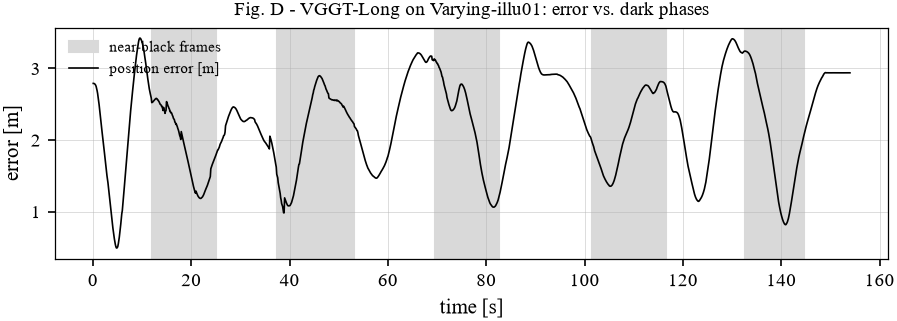

In [7]:
s = "Varying-illu01"
e, _ = aligned("vggt_long", s)
from evo.core import sync
r, a = sync.associate_trajectories(gt[s], e, max_diff=0.01)
err = np.linalg.norm(r.positions_xyz - a.positions_xyz, axis=1)
t0 = gt[s].timestamps[0]
fig, ax = plt.subplots(figsize=(7.16, 2.0))
ax.fill_between(light[s][:, 0], 0, 1, where=light[s][:, 2] > 0.8, color="0.85", transform=ax.get_xaxis_transform(),
                label="near-black frames")
ax.plot(r.timestamps - t0, err, c="k", lw=0.8, label="position error [m]")
ax.set_xlabel("time [s]"); ax.set_ylabel("error [m]"); ax.legend(fontsize=7, loc="upper left")
ax.set_title("Fig. D - VGGT-Long on Varying-illu01: error vs. dark phases", fontsize=9)
fig.savefig(FIG / "varying_error_vs_darkness.pdf")
dark = np.interp(r.timestamps - t0, light[s][:, 0], light[s][:, 2]) > 0.8
print(f"mean error in dark frames {err[dark].mean():.2f} m, in bright frames {err[~dark].mean():.2f} m")

## 5. Maps against the pseudo ground truth

`pipeline/map_eval.py` compares each map with the pseudo-GT map (Knapitsch et al. 2017): **accuracy** (map -> reference),
**completeness** (reference -> map), precision/recall/F-score at 5 and 10 cm, Chamfer distance. Both are the cloud-to-cloud
distances of CloudCompare (checked identical with `tools/cloudcompare_c2c.py`). The map is aligned via the trajectory and
refined with ICP. Two volumes: the whole **room** (a LiDAR also sees the ceiling) and **common**, floor to 2.5 m, the part a
forward-looking camera can observe at all.

In [8]:
mm = pd.read_csv(ROOT / "results" / "map_metrics.csv")
mm = mm[(mm.stage == "icp_refined") & mm.slug.isin(["vggt_long", "map_long", "map_long_calib", "map_long_sim3"])]
mm.pivot_table(index=["slug", "sequence"], columns="region",
               values=["accuracy_median_m", "completeness_median_m", "fscore_10cm"]).round(3)

accuracy_median_m         completeness_median_m  \
region                                   common    room                common   
slug           sequence                                                         
map_long       Dynamic01                  1.800   1.953                 0.093   
               Sha-turn01                11.197  11.325                 0.340   
               Varying-illu01             9.743  10.227                 0.941   
map_long_calib Dynamic01                  2.255   2.473                 0.105   
               Sha-turn01                 9.641  10.983                 0.162   
               Varying-illu01             8.081  10.456                 0.475   
vggt_long      Dynamic01                  0.030   0.031                 0.033   
               Sha-turn01                 0.047   0.052                 0.026   
               Varying-illu01             0.450   0.440                 3.233   

                                     fscore_10cm         
region                          room      common   room  
slug           sequence                                  
map_long       Dynamic01       0.225       0.137  0.091  
               Sha-turn01      0.437       0.015  0.007  
               Varying-illu01  0.771       0.012  0.002  
map_long_calib Dynamic01       0.246       0.121  0.077  
               Sha-turn01      0.368       0.032  0.012  
               Varying-illu01  0.390       0.011  0.003  
vggt_long      Dynamic01       0.727       0.740  0.454  
               Sha-turn01      0.534       0.713  0.476  
               Varying-illu01  4.335       0.016  0.008

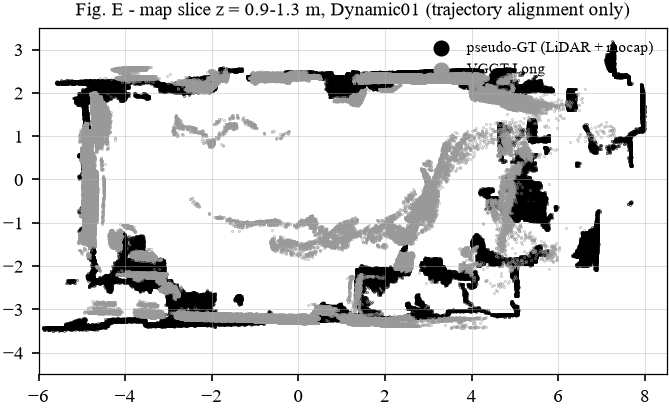

In [9]:
s = "Dynamic01"
_, (sc, R, t) = aligned("vggt_long", s)
v = _read_ply_xyzrgb(ROOT / "results" / "vggt_long" / s / "run_00" / "map.ply")[0]
v = (sc * v[::4]) @ R.T + t
fig, ax = plt.subplots(figsize=(7.16, 3.0))
for pts, c, lab in ((ref[s], "k", "pseudo-GT (LiDAR + mocap)"), (v, "0.6", "VGGT-Long")):
    sl = (pts[:, 2] > 0.9) & (pts[:, 2] < 1.3)
    ax.scatter(pts[sl, 0], pts[sl, 1], s=0.05, c=c, label=lab, rasterized=True)
ax.set_aspect("equal"); ax.set_xlim(-6, 8.5); ax.set_ylim(-4.5, 3.5); ax.legend(markerscale=30, fontsize=7, loc="upper right")
ax.set_title("Fig. E - map slice z = 0.9-1.3 m, Dynamic01 (trajectory alignment only)", fontsize=9)
fig.savefig(FIG / "map_overlay_dynamic01.pdf")

**Reading:** in the common volume half of VGGT-Long's points lie within 3-5 cm of the LiDAR reference (F-score 0.71-0.74
at 10 cm). Over the whole room completeness drops to 0.5-0.7 m because the camera never sees the ceiling - an honest
advantage of the LiDAR. VGGT-Long also maps the people walking through `Dynamic01` (curves inside the room in Fig. E);
the reference filtered them out, so they count as errors.

## 6. MapAnything in the same pipeline ("Map-Long")

The VGGT-Long repository can swap VGGT for **MapAnything**, which predicts metric depth. Upstream aligns its chunks with
**SE(3)** (no scale), and the result is evaluated with SE(3) like a metric sensor; Sim(3) is reported as well. Variants:
`map_long` (MapAnything estimates the intrinsics), `map_long_calib` (D435i intrinsics given), and the diagnostic
`map_long_sim3` (Sim(3) chunk alignment, deviating from upstream) - it separates "wrong metric scale" from "wrong geometry".

In [10]:
ml = metrics[metrics.slug.isin(["vggt_long", "map_long", "map_long_calib", "map_long_sim3"]) & (metrics.run == "run_00")]
ml.pivot_table(index="sequence", columns="slug", values=["ate_rmse_m", "ate_rmse_sim3_m", "scale_sim3"]).round(3)

ate_rmse_m                          ate_rmse_sim3_m  \
slug             map_long map_long_calib vggt_long        map_long   
sequence                                                             
Dynamic01           4.271          4.819     0.146           1.954   
Sha-turn01         12.391         12.172     0.264           1.908   
Varying-illu01     16.011         17.270     2.346           2.077   

                                        scale_sim3                           
slug           map_long_calib vggt_long   map_long map_long_calib vggt_long  
sequence                                                                     
Dynamic01               1.957     0.146      0.251          0.224     5.241  
Sha-turn01              1.881     0.264      0.072          0.077     5.811  
Varying-illu01          2.153     2.346      0.070          0.057     2.076

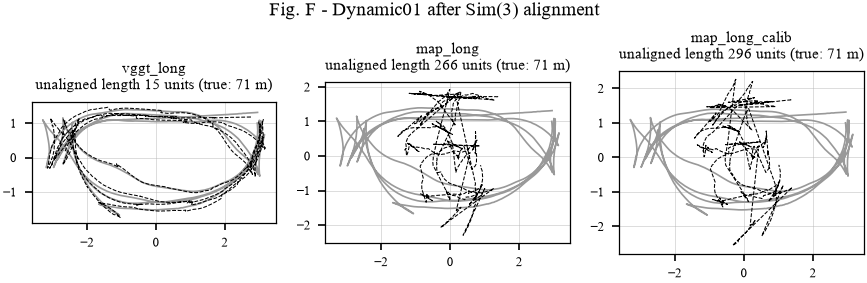

In [11]:
variants = [v for v in ["vggt_long", "map_long", "map_long_calib", "map_long_sim3"]
            if (ROOT / "results" / v / "Dynamic01" / "run_00" / "trajectory_tum.txt").exists()]
fig, axes = plt.subplots(1, len(variants), figsize=(7.16, 2.2))
for ax, v in zip(axes, variants):
    e, (sc, _, _) = aligned(v, "Dynamic01")
    raw = file_interface.read_tum_trajectory_file(str(ROOT / "results" / v / "Dynamic01" / "run_00" / "trajectory_tum.txt"))
    length = np.linalg.norm(np.diff(raw.positions_xyz, axis=0), axis=1).sum()
    ax.plot(gt["Dynamic01"].positions_xyz[::30, 0], gt["Dynamic01"].positions_xyz[::30, 1], c="0.6", lw=0.8)
    ax.plot(e.positions_xyz[:, 0], e.positions_xyz[:, 1], c="k", lw=0.5)
    ax.set_aspect("equal"); ax.tick_params(labelsize=6)
    ax.set_title(f"{v}\nunaligned length {length:.0f} units (true: 71 m)", fontsize=7)
fig.suptitle("Fig. F - Dynamic01 after Sim(3) alignment", fontsize=9)
fig.savefig(FIG / "map_long_dynamic01.pdf")

**Reading:** with SE(3) chunk alignment MapAnything's trajectories are 4-17x too long and jump at chunk borders:
overlapping chunks disagree by metres, i.e. the predicted metric scale changes from chunk to chunk. Known intrinsics do not
help. The diagnostic `map_long_sim3` shows how much of that is scale alone (see its row; if it is close to VGGT-Long, the
geometry within a chunk is fine and only the metric scale is unreliable for this low-mounted indoor camera).

## 7. Repeatability and resources

- **Deterministic:** the 5 VGGT-Long runs per sequence differ by < 0.1 mm (ATE IQR in Section 3), so repetitions add no
  information for this system; failures are systematic, not random.
- **GPU memory:** the upstream chunk size of 60 frames at 640x480 needs ~31.6 GB (first cluster run); a 16 GB laptop GPU
  runs out of memory, also with bfloat16 weights. Later values in `resources.csv` are unreliable, because the MIG-shared
  card reports the memory of neighbouring jobs.
- **Runtime:** ~14-20 min per sequence (1400-1750 frames) on a 48 GB MIG slice of an RTX PRO 6000 Blackwell; offline,
  not real time.

In [12]:
res = metrics[metrics.slug == "vggt_long"].groupby("sequence")[["wall_time_s"]].median()
res["frames"] = [len(list((DATA / s / "rgb_step3").glob("*.jpg"))) if (DATA / s / "rgb_step3").exists() else np.nan for s in res.index]
res["s_per_frame"] = res.wall_time_s / res.frames
res

,wall_time_s,frames,s_per_frame
sequence,,,
Dynamic01,975.030,1751,0.557
Sha-turn01,853.118,1389,0.614
Varying-illu01,888.644,1540,0.577


## 8. Take-aways

1. **Where it works, it works well.** With enough light VGGT-Long reaches 0.15-0.26 m ATE and maps the visible room to
   3-5 cm (median), from a single uncalibrated camera.
2. **Darkness causes a silent failure.** No "tracking lost": every frame gets a pose. The black chunks break the
   alignment between chunks, and the whole reconstruction shrinks - the error is as large in the bright parts as in the
   dark ones. The tracked fraction misses it; ATE, scale factor and map metrics show it. A deployment would need an explicit image-quality
   check - this is the lecturer's caveat about scene and lighting, made measurable.
3. **"Metric" foundation models do not deliver metric scale here.** MapAnything's scale varies between chunks by metres for
   this low indoor camera; with SE(3) chunk alignment the trajectory breaks, known intrinsics do not help.
4. **Map metrics need both directions.** Map-Long's huge, scattered clouds reach good completeness but terrible accuracy;
   only the F-score shows the failure.
5. **Cost.** Offline, ~0.6 s per frame on a 48 GB GPU; the default configuration does not fit a 16 GB laptop GPU.

Limitations: pseudo-GT from the same LiDAR family as LiDAR systems use, software-synchronised sensors, lever arm between
camera and mocap body (absorbed by ICP for maps, not for ATE), 10 Hz input (documented deviation), one room.